In [38]:
from common import Cubo, AjusteSARIMAX
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import statsmodels.api as sm

In [2]:
vegetacion_cubo = Cubo("data/vegetacion.csv", "data/tiempo.csv")
temperatura_cubo = Cubo("data/temperaturas.csv", "data/tiempo.csv")

## Gráfico de Correlación entre Temperaturas y Vegetación - Serie [0][0]

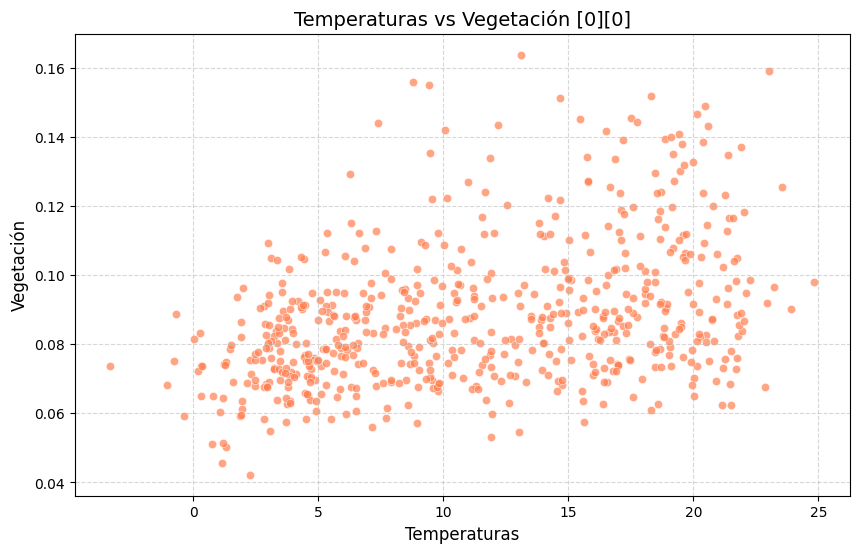

In [56]:

plt.figure(figsize=(10, 6))
sns.scatterplot(x=temperatura_cubo.datos[0, 0, :], y=vegetacion_cubo.datos[0,0,:], alpha=0.7, color='coral', edgecolor='w')

plt.title('Temperaturas vs Vegetación [0][0]', fontsize=14)
plt.xlabel('Temperaturas', fontsize=12)
plt.ylabel('Vegetación', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)


plt.show()

## Modelo SARIMAX

In [57]:
p, i, q = 3, 0, 0
P, I, Q, s = 0, 0, 0, 23

# Ajustar el modelo
modelo = SARIMAX(
    vegetacion_cubo.datos[0, 0, :], exog=temperatura_cubo.datos[0, 0, :],
    order=(p, i, q),
    seasonal_order=(P, I, Q, s),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)
ajuste = modelo.fit(disp=False)
print(ajuste.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  604
Model:               SARIMAX(3, 0, 0)   Log Likelihood                1697.576
Date:                Sun, 25 Oct 2026   AIC                          -3385.151
Time:                        11:45:43   BIC                          -3363.158
Sample:                             0   HQIC                         -3376.590
                                - 604                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0009      0.000      5.241      0.000       0.001       0.001
ar.L1          0.5578      0.037     14.906      0.000       0.484       0.631
ar.L2          0.2544      0.035      7.179      0.0

### Residuos

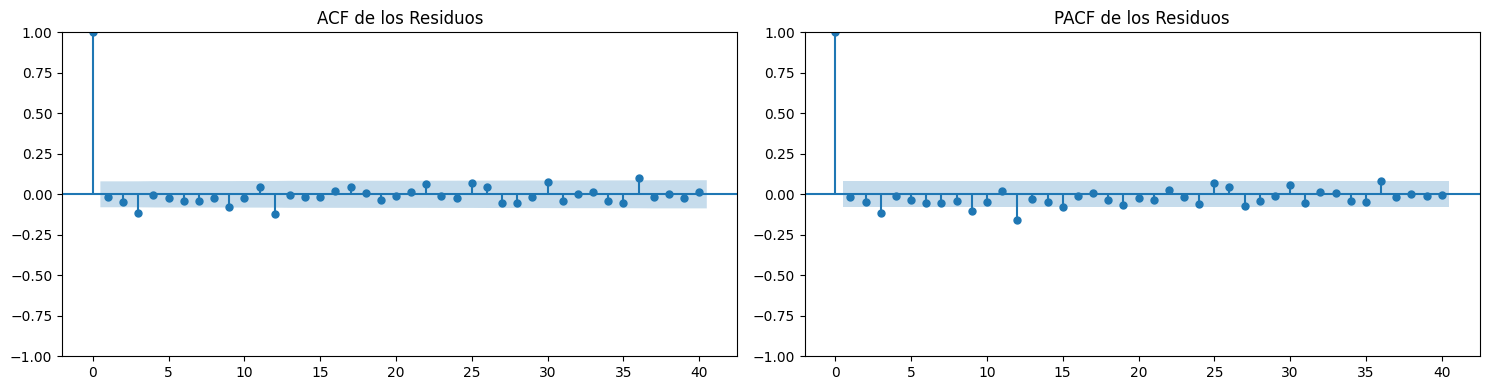

In [58]:
ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], ajuste, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos()

In [59]:
# Omitimos las primeras 50 observaciones para evitar la distorsión del período de inicialización con s=23
class GraficosAjuste:
    def ajuste_vs_datos(self, tiempo, x, y, ajuste, start_idx=46):

        tiempo_grafico = tiempo[start_idx:]
        prediccion = ajuste.get_prediction(exog=x)
        pred_media = prediccion.predicted_mean
        pred_ci = prediccion.conf_int(alpha=0.05)

        plt.figure(figsize=(15, 6))
        # Puntos en bruto de la serie original en azul
        plt.scatter(tiempo_grafico, np.array(y)[start_idx:], color='blue', alpha=0.5, s=15, label="Serie original (Y)")
        # Serie ajustada en color rojo
        plt.plot(tiempo_grafico, pred_media[start_idx:], color='red', label="Serie ajustada (SARIMAX)", linewidth=1.5)
        # Intervalo de confianza (95%)
        plt.fill_between(tiempo_grafico, pred_ci[start_idx:, 0], pred_ci[start_idx:, 1], color='red', alpha=0.15, label="Intervalo de confianza (95%)")

        plt.title("Ajuste del Modelo SARIMAX vs Serie Original (Excluyendo período de inicialización)", fontsize=14)
        plt.xlabel("Tiempo", fontsize=12)
        plt.ylabel("Y", fontsize=12)
        plt.legend(loc="upper right")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()

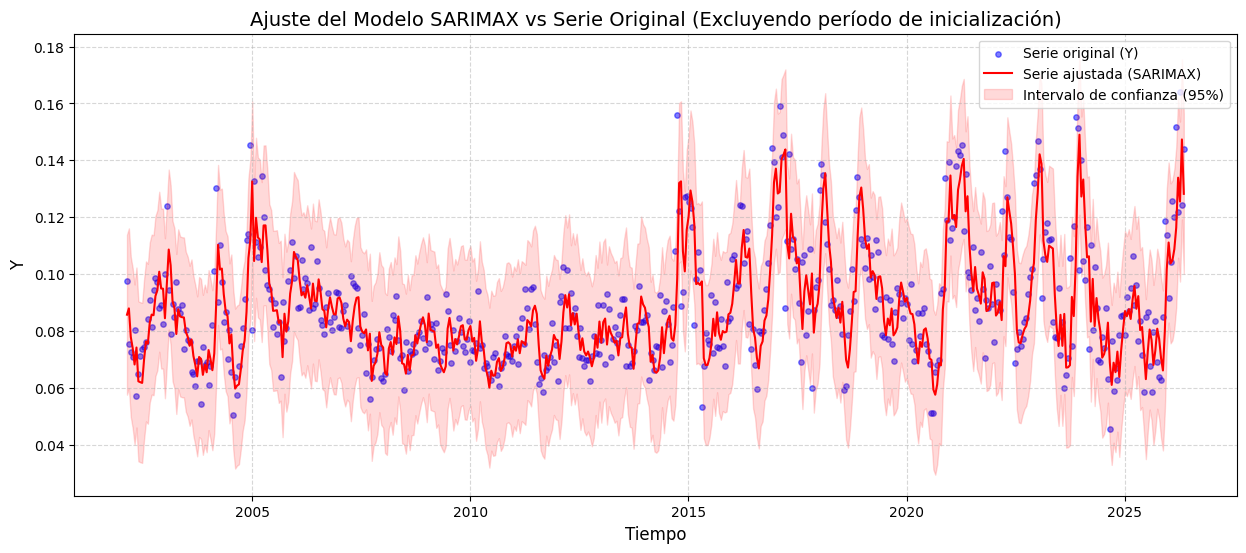

In [60]:
graficos = GraficosAjuste()
graficos.ajuste_vs_datos(temperatura_cubo.tiempo, temperatura_cubo.datos[0, 0, :], vegetacion_cubo.datos[0, 0, :], ajuste)

## SARIMAX + DLM

In [61]:

def matriz_lags(x, L0=0, L1=2):
    """
    Genera una matriz de retardos para la variable x desde el lag L0 hasta el lag L1.
    """
    x = np.asarray(x)
    n = len(x)
    # El retardo máximo determina cuántas observaciones perdemos al inicio
    Z = np.column_stack([
        x[L1-lag:n-lag] if lag > 0 else x[L1:n]
        for lag in range(L0, L1+1)
    ])
    return Z, np.arange(L1, n)

L0 = 1
L1 = 3
L = L1 - L0 + 1
Xlags, idx = matriz_lags(temperatura_cubo.datos[0, 0, :], L0, L1)
# Convertimos Y a un array de numpy antes de indexar con el array idx
Y_dlm = np.asarray(vegetacion_cubo.datos[0, 0, :])[idx]
X = np.array(temperatura_cubo.datos[0, 0, :])
print(Xlags.shape)


(601, 3)


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.172
Model:                            OLS   Adj. R-squared:                  0.168
Method:                 Least Squares   F-statistic:                     41.35
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           2.74e-24
Time:                        11:46:17   Log-Likelihood:                 1541.0
No. Observations:                 601   AIC:                            -3074.
Df Residuals:                     597   BIC:                            -3056.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0730      0.002     45.540      0.0

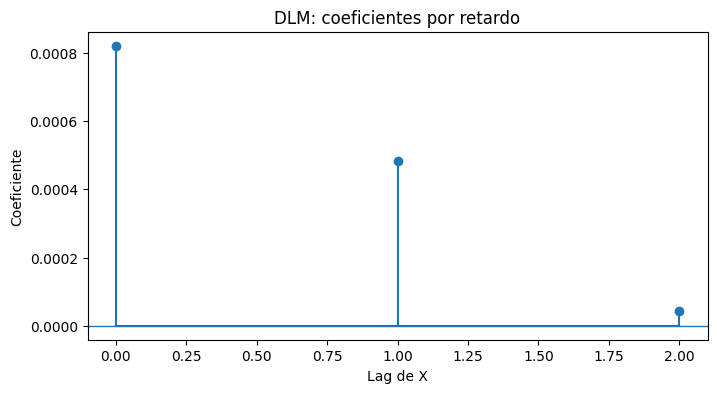

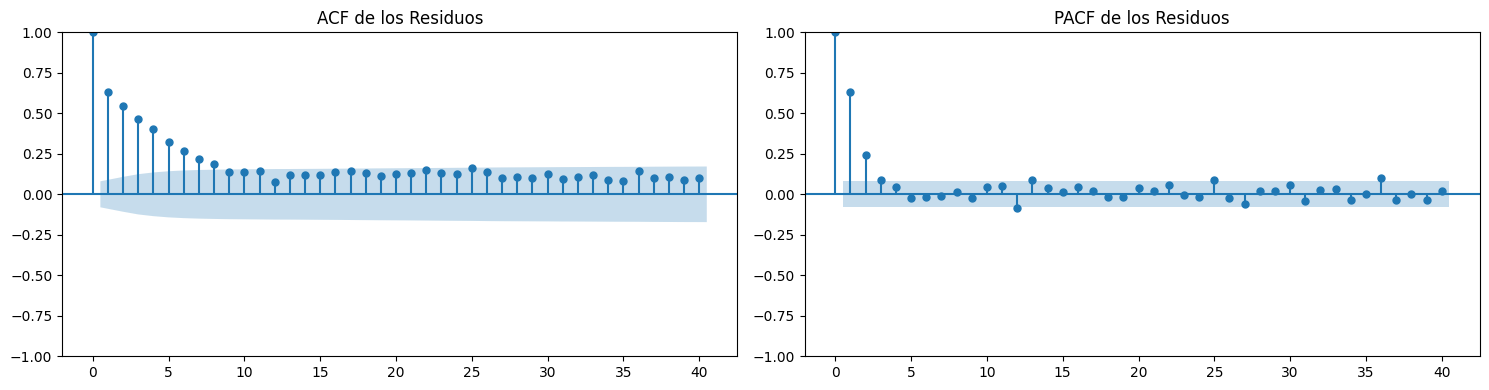

In [62]:
dlm = sm.OLS(Y_dlm, sm.add_constant(Xlags)).fit()
print(dlm.summary())

beta_dlm = dlm.params[1:]

plt.figure(figsize=(8,4))
plt.stem(np.arange(L), beta_dlm)
plt.axhline(0, linewidth=1)
plt.xlabel("Lag de X")
plt.ylabel("Coeficiente")
plt.title("DLM: coeficientes por retardo")
plt.show()

# Gráficos de ACF y PACF de los residuos del DLM
ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], dlm, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  601
Model:               SARIMAX(3, 0, 0)   Log Likelihood                1712.238
Date:                Sun, 25 Oct 2026   AIC                          -3408.476
Time:                        11:46:35   BIC                          -3373.328
Sample:                             0   HQIC                         -3394.792
                                - 601                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0177      0.003      6.628      0.000       0.012       0.023
x1             0.0004      0.000      1.702      0.089   -6.22e-05       0.001
x2             0.0005      0.000      1.950      0.0

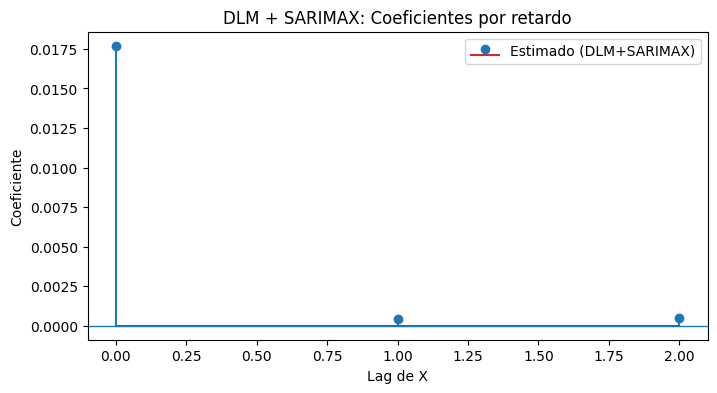

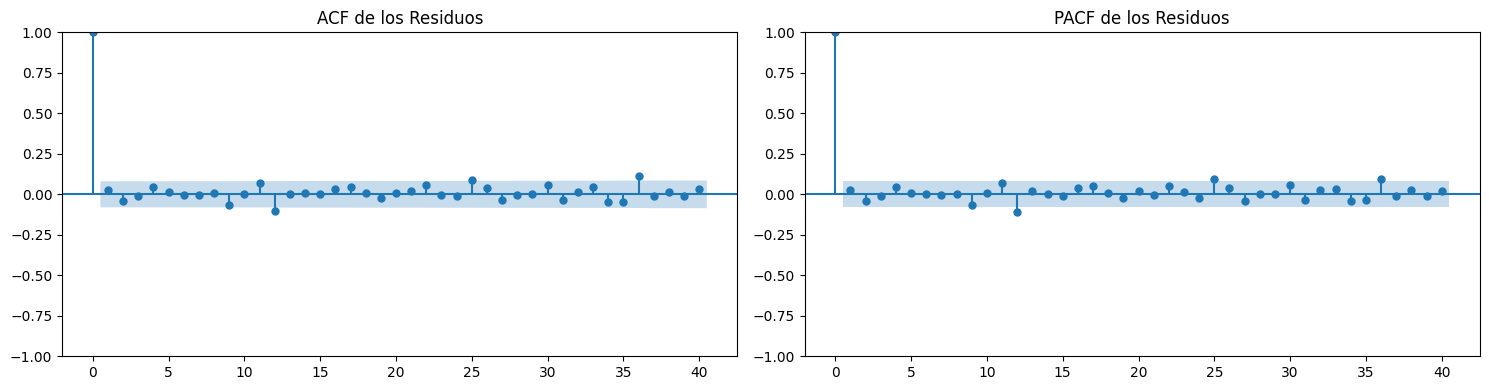

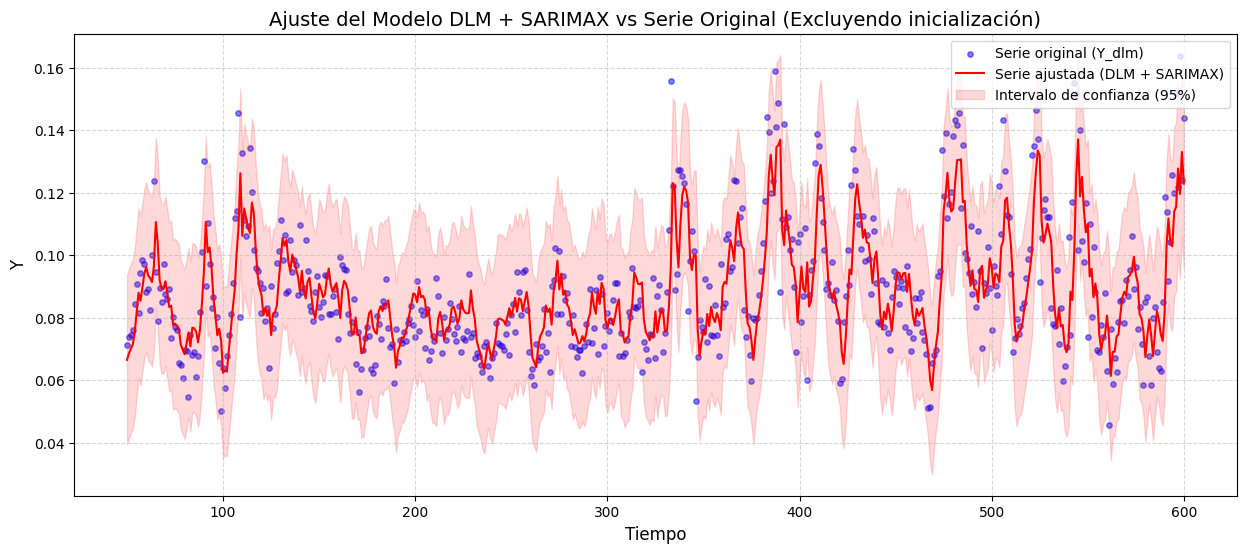

In [63]:
# Ajustar el modelo DLM + SARIMAX usando la estructura SARIMAX(1,0,1)(1,0,1)23
modelo_dlm_sarimax = SARIMAX(
    Y_dlm,
    exog=Xlags,
    order=(3, 0, 0),
    seasonal_order=(0, 0, 0, 23),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste_dlm_sarimax = modelo_dlm_sarimax.fit(disp=False)
print(ajuste_dlm_sarimax.summary())

# Obtener coeficientes estimados para los retardos
beta_sarimax = ajuste_dlm_sarimax.params[:L]

# Gráfica de coeficientes por retardo
plt.figure(figsize=(8,4))
plt.stem(np.arange(L), beta_sarimax, label="Estimado (DLM+SARIMAX)")
plt.axhline(0, linewidth=1)
plt.xlabel("Lag de X")
plt.ylabel("Coeficiente")
plt.title("DLM + SARIMAX: Coeficientes por retardo")
plt.legend()
plt.show()

ajuste_sarimax = AjusteSARIMAX(vegetacion_cubo.datos[0, 0, :], ajuste_dlm_sarimax, "Ajuste SARIMAX")
ajuste_sarimax.graficos_residuos()

# 2. Serie temporal ajustada vs Serie Original
prediccion = ajuste_dlm_sarimax.get_prediction(exog=Xlags)
pred_media = prediccion.predicted_mean
pred_ci = prediccion.conf_int(alpha=0.05)

# Omitimos las primeras 50 observaciones debido a la inicialización con s=23
start_idx = 50
tiempo_grafico = range(start_idx, len(Y_dlm))

plt.figure(figsize=(15, 6))
plt.scatter(tiempo_grafico, np.array(Y_dlm)[start_idx:], color='blue', alpha=0.5, s=15, label="Serie original (Y_dlm)")
plt.plot(tiempo_grafico, pred_media[start_idx:], color='red', label="Serie ajustada (DLM + SARIMAX)", linewidth=1.5)
plt.fill_between(tiempo_grafico, pred_ci[start_idx:, 0], pred_ci[start_idx:, 1], color='red', alpha=0.15, label="Intervalo de confianza (95%)")

plt.title("Ajuste del Modelo DLM + SARIMAX vs Serie Original (Excluyendo inicialización)", fontsize=14)
plt.xlabel("Tiempo", fontsize=12)
plt.ylabel("Y", fontsize=12)
plt.legend(loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()